# A Tour of Classification Models — Credit Risk Edition (Home Credit Default Risk)

Second of three credit-risk notebooks: **Logistic Regression → L2/L1/Elastic-Net
Logistic → MLP → Random Forest → XGBoost → CatBoost → LightGBM**, each tuned via
`RandomizedSearchCV` with a compact parameter search.

**Dataset:** [Home Credit Default Risk](https://www.kaggle.com/competitions/home-credit-default-risk)
(Kaggle competition) — **307,511 loan applications**, **122 columns**, predicting
**`TARGET`**: did this applicant have payment difficulties (0 = repaid fine,
1 = had difficulty)?

**What's new here vs. Give Me Some Credit:**
- **12x more features** (122 vs. 10), a genuine mix of numeric and **16 categorical
  columns** — CatBoost's native categorical handling gets exercised here, the
  credit-risk series' own version of the lesson from the sailing-boats and
  crypto notebooks.
- **Real, uneven missingness** — 41 columns are more than 50% empty (mostly
  building/apartment-detail fields that simply don't apply to every applicant),
  which we drop rather than weakly impute; the rest get median/mode imputation.
- **This is only the competition's main table.** The real competition links six
  more files (credit bureau history, previous loan applications, monthly balance
  snapshots, …) for a genuinely larger feature-engineering exercise — out of
  scope here, noted explicitly rather than silently ignored.
- **Data used:** the complete main application table, with a stratified train–test split.

Imbalance here (8.1% positive) sits between Give Me Some Credit (6.7%) and AmEx
(24.6%, next notebook) — all three use the same classification toolkit, on three
genuinely different real-world severity levels of the same underlying problem.


## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score,
                              recall_score, f1_score, log_loss, roc_curve,
                              confusion_matrix)


from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)


Searches use two candidates and two cross-validation folds. Every selected model refits on the complete training partition.

## 2. Load and clean the data

Columns more than 50% empty (mostly building/apartment-quality fields — not every
applicant lives in a building with recorded common-area/floor-material details)
are dropped outright rather than weakly imputed. Everything else: numeric columns
get median imputation, categorical columns get an explicit `"Missing"` category
(categorical missingness can itself be informative — e.g. `EMERGENCYSTATE_MODE`
being unset likely correlates with building type).


In [2]:
raw = pd.read_csv("home_credit_application_train.csv")
print(raw.shape)
raw[["SK_ID_CURR", "TARGET", "CODE_GENDER", "NAME_EDUCATION_TYPE", "AMT_INCOME_TOTAL", "DAYS_BIRTH"]].head()


(307511, 122)


,SK_ID_CURR,TARGET,CODE_GENDER,NAME_EDUCATION_TYPE,AMT_INCOME_TOTAL,DAYS_BIRTH
0,100002,1,M,Secondary / secondary special,202500.0,-9461
1,100003,0,F,Higher education,270000.0,-16765
2,100004,0,M,Secondary / secondary special,67500.0,-19046
3,100006,0,F,Secondary / secondary special,135000.0,-19005
4,100007,0,M,Secondary / secondary special,121500.0,-19932


In [3]:
df = raw.drop(columns=["SK_ID_CURR"]).copy()

# Two well-documented Home Credit data quirks, both of which badly distort a
# gradient-based linear model's optimization landscape if left untouched:
# 1. DAYS_EMPLOYED uses 365243 (~1,000 years) as a sentinel for "not currently
#    employed" (retirees, etc.) -- 18% of rows. Treat as missing.
n_sentinel = (df["DAYS_EMPLOYED"] == 365243).sum()
df.loc[df["DAYS_EMPLOYED"] == 365243, "DAYS_EMPLOYED"] = np.nan
print(f"DAYS_EMPLOYED: {n_sentinel} sentinel (365243) values -> NaN")

# Cap extreme income values at the 99th percentile.
cap = df["AMT_INCOME_TOTAL"].quantile(0.99)
n_capped = (df["AMT_INCOME_TOTAL"] > cap).sum()
df["AMT_INCOME_TOTAL"] = df["AMT_INCOME_TOTAL"].clip(upper=cap)
print(f"AMT_INCOME_TOTAL: {n_capped} values above the 99th percentile ({cap:,.0f}) capped")

miss_frac = df.isna().mean()
drop_cols = miss_frac[miss_frac > 0.5].index.tolist()
df = df.drop(columns=drop_cols)
print(f"Dropped {len(drop_cols)} columns more than 50% missing.")

categorical_features = df.select_dtypes(include=["object", "str", "category"]).columns.tolist()
numeric_features = [c for c in df.columns if c not in categorical_features + ["TARGET"]]

for c in numeric_features:
    df[c] = df[c].fillna(df[c].median())
for c in categorical_features:
    df[c] = df[c].fillna("Missing")

print(f"Final shape: {df.shape}  ({len(numeric_features)} numeric, {len(categorical_features)} categorical features)")

X = df[numeric_features + categorical_features]
y = df["TARGET"]
print(f"Using all {len(X):,} applications")
print(f"Class balance: {y.value_counts(normalize=True).to_dict()}")


DAYS_EMPLOYED: 55374 sentinel (365243) values -> NaN
AMT_INCOME_TOTAL: 3014 values above the 99th percentile (472,500) capped
Dropped 41 columns more than 50% missing.


Final shape: (307511, 80)  (66 numeric, 13 categorical features)
Using all 307,511 applications
Class balance: {0: 0.9192711805431351, 1: 0.08072881945686496}


### Quick EDA

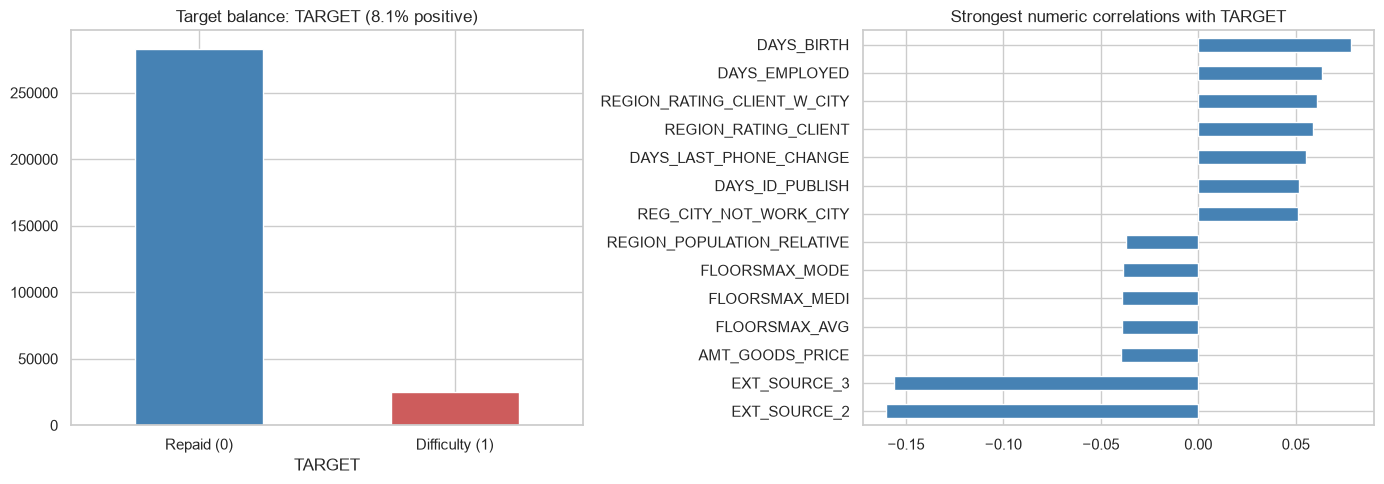

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

y.value_counts().plot(kind="bar", ax=axes[0], color=["steelblue", "indianred"])
axes[0].set_title(f"Target balance: TARGET ({y.mean():.1%} positive)")
axes[0].set_xticklabels(["Repaid (0)", "Difficulty (1)"], rotation=0)

top_corr = df[numeric_features + ["TARGET"]].corr(numeric_only=True)["TARGET"].drop("TARGET")
top_corr = pd.concat([top_corr.nsmallest(7), top_corr.nlargest(7)]).sort_values()
top_corr.plot(kind="barh", ax=axes[1], color="steelblue")
axes[1].set_title("Strongest numeric correlations with TARGET")

plt.tight_layout()
plt.show()


`DAYS_BIRTH` and `DAYS_EMPLOYED` (both stored as *negative* days before the
application, a real quirk of this dataset's encoding) show up among the strongest
signals — older applicants with longer employment histories default less often,
which matches financial intuition directly.


## 3. Train / test split and preprocessing

Same two-track `ColumnTransformer` pattern as the sailing-boats and crypto
notebooks: scaled + one-hot encoded for Logistic Regression/MLP, unscaled but
encoded for Random Forest/XGBoost/LightGBM, raw columns + `cat_features` for
CatBoost. `stratify=y` and `StratifiedKFold` preserve the 8.1% positive rate
across every split and CV fold, as in Give Me Some Credit.


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

preprocess_scaled = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])
X_train_scaled = preprocess_scaled.fit_transform(X_train)
X_test_scaled = preprocess_scaled.transform(X_test)
scaled_feature_names = preprocess_scaled.get_feature_names_out()

preprocess_tree = ColumnTransformer([
    ("num", "passthrough", numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])
X_train_enc = preprocess_tree.fit_transform(X_train)
X_test_enc = preprocess_tree.transform(X_test)
tree_feature_names = preprocess_tree.get_feature_names_out()

cat_feature_idx = [X_train.columns.get_loc(c) for c in categorical_features]

skf = StratifiedKFold(n_splits=2, shuffle=True, random_state=RANDOM_STATE)
skf3 = StratifiedKFold(n_splits=2, shuffle=True, random_state=RANDOM_STATE)

print(f"Train: {X_train.shape} ({y_train.mean():.2%} positive)")
print(f"Test:  {X_test.shape} ({y_test.mean():.2%} positive)")
print(f"Scaled/encoded feature count: {X_train_scaled.shape[1]}")


Train: (246008, 79) (8.07% positive)
Test:  (61503, 79) (8.07% positive)
Scaled/encoded feature count: 195


In [6]:
results = {}

def evaluate(name, y_true, y_pred_proba, threshold=0.5):
    y_pred = (y_pred_proba >= threshold).astype(int)
    metrics = {
        "ROC_AUC": roc_auc_score(y_true, y_pred_proba),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "LogLoss": log_loss(y_true, y_pred_proba),
    }
    results[name] = metrics
    print(f"{name:20s}  ROC_AUC={metrics['ROC_AUC']:.4f}  F1={metrics['F1']:.4f}  "
          f"Precision={metrics['Precision']:.4f}  Recall={metrics['Recall']:.4f}")
    return metrics


## 4. Logistic Regression


In [7]:
log_reg = LogisticRegression(C=np.inf, max_iter=2000, random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)
y_proba_lr = log_reg.predict_proba(X_test_scaled)[:, 1]
evaluate("LogisticRegression", y_test, y_proba_lr)


LogisticRegression    ROC_AUC=0.7459  F1=0.0229  Precision=0.5577  Recall=0.0117


{'ROC_AUC': 0.7459082586560414,
 'Accuracy': 0.9194673430564363,
 'Precision': 0.5576923076923077,
 'Recall': 0.011681772406847936,
 'F1': 0.02288419806667982,
 'LogLoss': 0.24963839883446673}

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98159/628306305.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_df, x="coefficient", y="feature", palette="viridis")


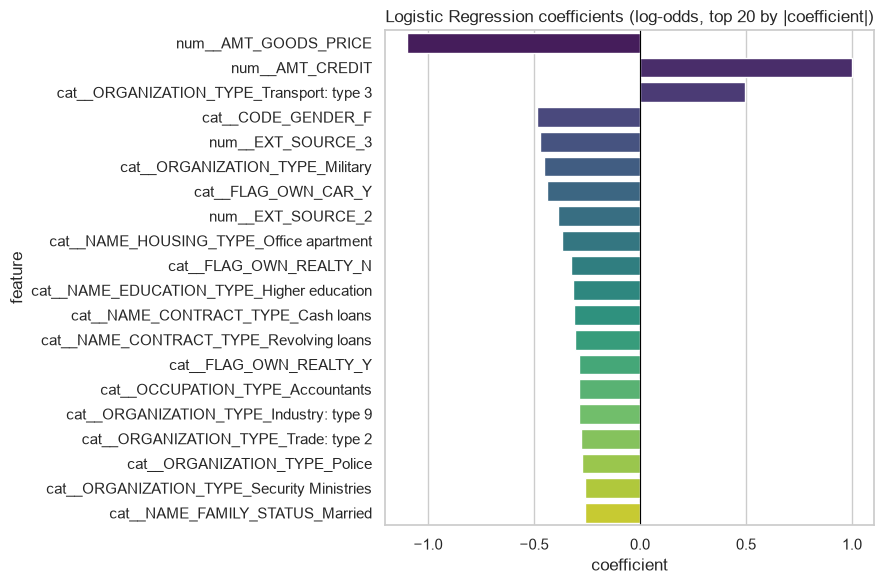

,feature,coefficient
4,num__AMT_GOODS_PRICE,-1.097207
2,num__AMT_CREDIT,0.999251
188,cat__ORGANIZATION_TYPE_Transport: type 3,0.497457
68,cat__CODE_GENDER_F,-0.484402
27,num__EXT_SOURCE_3,-0.471931
165,cat__ORGANIZATION_TYPE_Military,-0.453952
72,cat__FLAG_OWN_CAR_Y,-0.440231
26,num__EXT_SOURCE_2,-0.386711
105,cat__NAME_HOUSING_TYPE_Office apartment,-0.365764
73,cat__FLAG_OWN_REALTY_N,-0.326649


In [8]:
coef_df = pd.DataFrame({"feature": scaled_feature_names, "coefficient": log_reg.coef_[0]}
                       ).sort_values("coefficient", key=abs, ascending=False).head(20)
plt.figure(figsize=(9, 6))
sns.barplot(data=coef_df, x="coefficient", y="feature", palette="viridis")
plt.title("Logistic Regression coefficients (log-odds, top 20 by |coefficient|)")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()
coef_df


## 5. Regularized Logistic Regression: L2, L1 & Elastic Net

With 141 one-hot encoded columns feeding into the model, regularization has
considerably more room to matter than it did on Give Me Some Credit's 10 clean
numeric features.


In [9]:
Cs = np.logspace(-2, 2, 3)

l2_logreg = LogisticRegressionCV(Cs=Cs, l1_ratios=[0.0], use_legacy_attributes=False, solver="lbfgs", cv=skf3,
                                  scoring="roc_auc", max_iter=2000, random_state=RANDOM_STATE,
                                  n_jobs=2, tol=1e-2)
l2_logreg.fit(X_train_scaled, y_train)
y_proba_l2 = l2_logreg.predict_proba(X_test_scaled)[:, 1]
evaluate("LogReg (L2)", y_test, y_proba_l2)
print(f"Chosen C: {l2_logreg.C_:.4f}")


LogReg (L2)           ROC_AUC=0.7289  F1=0.0052  Precision=0.4333  Recall=0.0026
Chosen C: 0.0100


In [10]:
l1_logreg = LogisticRegressionCV(Cs=Cs, l1_ratios=[1.0], use_legacy_attributes=False, solver="liblinear", cv=skf3,
                                  scoring="roc_auc", max_iter=2000, random_state=RANDOM_STATE,
                                  n_jobs=2, tol=1e-2)
l1_logreg.fit(X_train_scaled, y_train)
y_proba_l1 = l1_logreg.predict_proba(X_test_scaled)[:, 1]
evaluate("LogReg (L1)", y_test, y_proba_l1)
print(f"Chosen C: {l1_logreg.C_:.4f}")
print(f"Features zeroed out: {(l1_logreg.coef_[0] == 0).sum()} / {len(scaled_feature_names)}")


LogReg (L1)           ROC_AUC=0.7443  F1=0.0194  Precision=0.5444  Recall=0.0099
Chosen C: 1.0000
Features zeroed out: 9 / 195


In [11]:
elastic_logreg = LogisticRegressionCV(
    Cs=np.logspace(-2, 2, 3), use_legacy_attributes=False, solver="saga", l1_ratios=[.5],
    cv=skf3, scoring="roc_auc", max_iter=2000, random_state=RANDOM_STATE,
    n_jobs=2, tol=1e-2,
)
elastic_logreg.fit(X_train_scaled, y_train)
y_proba_elastic = elastic_logreg.predict_proba(X_test_scaled)[:, 1]
evaluate("LogReg (ElasticNet)", y_test, y_proba_elastic)
print(f"Chosen C: {elastic_logreg.C_:.4f}, l1_ratio: {elastic_logreg.l1_ratio_:.2f}")


LogReg (ElasticNet)   ROC_AUC=0.7370  F1=0.0104  Precision=0.4561  Recall=0.0052
Chosen C: 100.0000, l1_ratio: 0.50


On a 141-column one-hot encoded feature set, L1/Elastic Net typically zero
out a real chunk of the rarer `ORGANIZATION_TYPE` dummy columns — the kind of
sparse, low-prevalence categories regularization is specifically good at pruning.


## 6. K-Nearest Neighbors (KNN)

A genuinely different kind of model from everything else in this notebook: KNN
has no coefficients and builds no trees. It predicts a point's class
probability from the (optionally distance-weighted) vote of its `k` nearest
training points in feature space — "nearest" measured on the *scaled* features
(the same `X_train_scaled`/`X_test_scaled` used by the logistic regression
variants and MLP above), since distance is meaningless once features sit on
wildly different raw scales.

**When to reach for it:** a quick, assumption-light baseline — no linearity, no
tree-splittable structure, nothing learned at "training" time (there's no
training at all; `.fit()` just stores the data).

**Key hyperparameters:**
- `n_neighbors` (k): more neighbors → smoother, more biased predictions; fewer →
  noisier, more variance.
- `weights`: `"uniform"` averages neighbors equally; `"distance"` weights closer
  neighbors more heavily.
- `p`: the distance metric's power — `1` = Manhattan, `2` = Euclidean.

**Limitations:** prediction is slow on large datasets (every query compares
against the full training set); accuracy degrades in high dimensions (the
"curse of dimensionality" — with enough dimensions, every point ends up roughly
equidistant from every other).


In [12]:
knn = KNeighborsClassifier(n_neighbors=15, weights="distance")
knn.fit(X_train_scaled, y_train)

y_proba_knn = knn.predict_proba(X_test_scaled)[:, 1]
evaluate("KNN", y_test, y_proba_knn)


KNN                   ROC_AUC=0.6416  F1=0.0060  Precision=0.3846  Recall=0.0030


{'ROC_AUC': 0.6415521583982569,
 'Accuracy': 0.9191258962977416,
 'Precision': 0.38461538461538464,
 'Recall': 0.0030211480362537764,
 'F1': 0.005995203836930456,
 'LogLoss': 0.8148754352999926}

### Hyperparameter tuning with `GridSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [13]:
knn_param_grid = {'n_neighbors': [5, 15], 'weights': ['distance'], 'p': [2]}


knn_grid = GridSearchCV(
    KNeighborsClassifier(),
    param_grid=knn_param_grid,
    cv=skf3,
    scoring="roc_auc",
    n_jobs=2,
)
knn_grid.fit(X_train_scaled, y_train)

print(f"Best params: {knn_grid.best_params_}")
print(f"Best CV ROC-AUC: {knn_grid.best_score_:.4f}")


Best params: {'n_neighbors': 15, 'p': 2, 'weights': 'distance'}
Best CV ROC-AUC: 0.6308


In [14]:
y_proba_knn_tuned = knn_grid.best_estimator_.predict_proba(X_test_scaled)[:, 1]
evaluate("KNN (tuned)", y_test, y_proba_knn_tuned)


KNN (tuned)           ROC_AUC=0.6416  F1=0.0060  Precision=0.3846  Recall=0.0030


{'ROC_AUC': 0.6415521583982569,
 'Accuracy': 0.9191258962977416,
 'Precision': 0.38461538461538464,
 'Recall': 0.0030211480362537764,
 'F1': 0.005995203836930456,
 'LogLoss': 0.8148754352999926}

## 7. MLP (Multi-Layer Perceptron)


In [15]:
mlp = MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", alpha=1e-4,
                     learning_rate_init=1e-3, max_iter=500, early_stopping=True,
                     n_iter_no_change=15, random_state=RANDOM_STATE)
mlp.fit(X_train_scaled, y_train)
y_proba_mlp = mlp.predict_proba(X_test_scaled)[:, 1]
evaluate("MLP", y_test, y_proba_mlp)


MLP                   ROC_AUC=0.7432  F1=0.0147  Precision=0.4568  Recall=0.0075


{'ROC_AUC': 0.7431767179054543,
 'Accuracy': 0.9191584150366648,
 'Precision': 0.4567901234567901,
 'Recall': 0.0074521651560926485,
 'F1': 0.01466508125247721,
 'LogLoss': 0.2526334681582281}

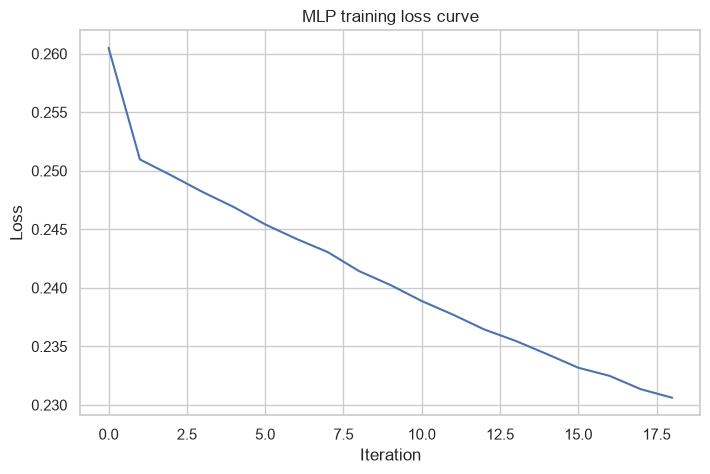

In [16]:
plt.plot(mlp.loss_curve_)
plt.title("MLP training loss curve")
plt.xlabel("Iteration"); plt.ylabel("Loss")
plt.show()


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [17]:
mlp_param_dist = {'hidden_layer_sizes': [(64, 32)], 'alpha': [0.0001, 0.001]}


mlp_search = RandomizedSearchCV(
    MLPClassifier(activation="relu", learning_rate_init=1e-3, max_iter=500,
                  early_stopping=True, n_iter_no_change=15, random_state=RANDOM_STATE),
    param_distributions=mlp_param_dist, n_iter=2, cv=skf3, scoring="roc_auc",
    n_jobs=2, random_state=RANDOM_STATE,
)
mlp_search.fit(X_train_scaled, y_train)
print(f"Best params: {mlp_search.best_params_}")
print(f"Best CV ROC-AUC: {mlp_search.best_score_:.4f}")


Best params: {'hidden_layer_sizes': (64, 32), 'alpha': 0.001}
Best CV ROC-AUC: 0.7361


In [18]:
y_proba_mlp_tuned = mlp_search.best_estimator_.predict_proba(X_test_scaled)[:, 1]
evaluate("MLP (tuned)", y_test, y_proba_mlp_tuned)


MLP (tuned)           ROC_AUC=0.7400  F1=0.0480  Precision=0.4360  Recall=0.0254


{'ROC_AUC': 0.7399530663493014,
 'Accuracy': 0.9186706339528153,
 'Precision': 0.4359861591695502,
 'Recall': 0.025377643504531724,
 'F1': 0.04796345641416064,
 'LogLoss': 0.25319293027799367}

## 8. Random Forest


In [19]:
rf = RandomForestClassifier(n_estimators=300, max_depth=None, min_samples_leaf=2,
                             n_jobs=2, random_state=RANDOM_STATE)
rf.fit(X_train_enc, y_train)
y_proba_rf = rf.predict_proba(X_test_enc)[:, 1]
evaluate("RandomForest", y_test, y_proba_rf)


RandomForest          ROC_AUC=0.7313  F1=0.0004  Precision=1.0000  Recall=0.0002


{'ROC_AUC': 0.7313019446287086,
 'Accuracy': 0.9192884899923581,
 'Precision': 1.0,
 'Recall': 0.0002014098690835851,
 'F1': 0.0004027386226339106,
 'LogLoss': 0.2536532058295237}

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98159/3683593754.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=rf_importance, x="importance", y="feature", palette="viridis")


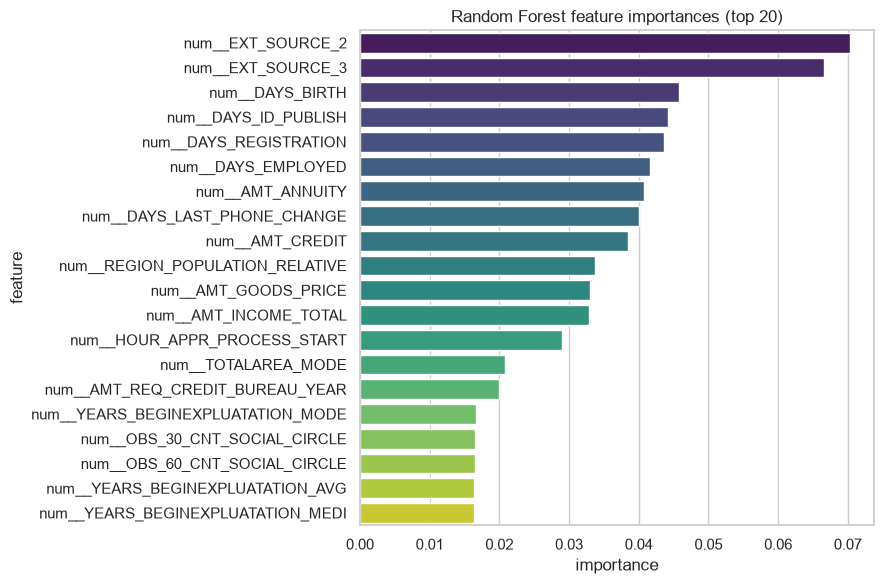

,feature,importance
26,num__EXT_SOURCE_2,0.070234
27,num__EXT_SOURCE_3,0.066544
6,num__DAYS_BIRTH,0.045800
9,num__DAYS_ID_PUBLISH,0.044138
8,num__DAYS_REGISTRATION,0.043688
7,num__DAYS_EMPLOYED,0.041671
3,num__AMT_ANNUITY,0.040724
39,num__DAYS_LAST_PHONE_CHANGE,0.040100
2,num__AMT_CREDIT,0.038492
5,num__REGION_POPULATION_RELATIVE,0.033786


In [20]:
rf_importance = pd.DataFrame({"feature": tree_feature_names, "importance": rf.feature_importances_}
                             ).sort_values("importance", ascending=False).head(20)
plt.figure(figsize=(9, 6))
sns.barplot(data=rf_importance, x="importance", y="feature", palette="viridis")
plt.title("Random Forest feature importances (top 20)")
plt.tight_layout()
plt.show()
rf_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [21]:
rf_param_dist = {'n_estimators': [300], 'max_depth': [8, 12], 'min_samples_leaf': [2, 5]}


rf_search = RandomizedSearchCV(
    RandomForestClassifier(n_jobs=2, random_state=RANDOM_STATE),
    param_distributions=rf_param_dist, n_iter=2, cv=skf3, scoring="roc_auc",
    n_jobs=2, random_state=RANDOM_STATE,
)
rf_search.fit(X_train_enc, y_train)
print(f"Best params: {rf_search.best_params_}")
print(f"Best CV ROC-AUC: {rf_search.best_score_:.4f}")


Best params: {'n_estimators': 300, 'min_samples_leaf': 5, 'max_depth': 12}
Best CV ROC-AUC: 0.7326


In [22]:
y_proba_rf_tuned = rf_search.best_estimator_.predict_proba(X_test_enc)[:, 1]
evaluate("RandomForest (tuned)", y_test, y_proba_rf_tuned)


RandomForest (tuned)  ROC_AUC=0.7394  F1=0.0000  Precision=0.0000  Recall=0.0000


{'ROC_AUC': 0.7394335537128786,
 'Accuracy': 0.9192722306228964,
 'Precision': 0.0,
 'Recall': 0.0,
 'F1': 0.0,
 'LogLoss': 0.25566439244498473}

## 9. XGBoost (Extreme Gradient Boosting)


In [23]:
xgb = XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=5,
                    subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                    eval_metric="auc", random_state=RANDOM_STATE, n_jobs=2)
xgb.fit(X_train_enc, y_train, eval_set=[(X_test_enc, y_test)], verbose=False)
y_proba_xgb = xgb.predict_proba(X_test_enc)[:, 1]
evaluate("XGBoost", y_test, y_proba_xgb)


XGBoost               ROC_AUC=0.7579  F1=0.0374  Precision=0.5581  Recall=0.0193


{'ROC_AUC': 0.7579147580767804,
 'Accuracy': 0.9195974180121295,
 'Precision': 0.5581395348837209,
 'Recall': 0.01933534743202417,
 'F1': 0.03737590033093245,
 'LogLoss': 0.2459821254014969}

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98159/3336586695.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=xgb_importance, x="importance", y="feature", palette="viridis")


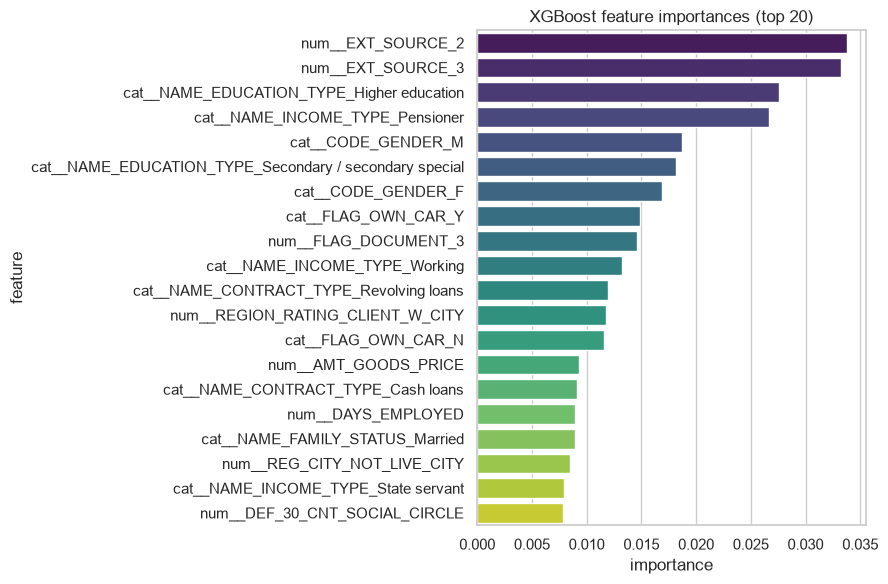

,feature,importance
26,num__EXT_SOURCE_2,0.033800
27,num__EXT_SOURCE_3,0.033221
92,cat__NAME_EDUCATION_TYPE_Higher education,0.027572
86,cat__NAME_INCOME_TYPE_Pensioner,0.026626
69,cat__CODE_GENDER_M,0.018731
95,cat__NAME_EDUCATION_TYPE_Secondary / secondary...,0.018146
68,cat__CODE_GENDER_F,0.016891
72,cat__FLAG_OWN_CAR_Y,0.014839
41,num__FLAG_DOCUMENT_3,0.014557
90,cat__NAME_INCOME_TYPE_Working,0.013246


In [24]:
xgb_importance = pd.DataFrame({"feature": tree_feature_names, "importance": xgb.feature_importances_}
                              ).sort_values("importance", ascending=False).head(20)
plt.figure(figsize=(9, 6))
sns.barplot(data=xgb_importance, x="importance", y="feature", palette="viridis")
plt.title("XGBoost feature importances (top 20)")
plt.tight_layout()
plt.show()
xgb_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [25]:
xgb_param_dist = {'n_estimators': [500], 'max_depth': [3, 5], 'learning_rate': [0.03, 0.05]}


xgb_search = RandomizedSearchCV(
    XGBClassifier(subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
                  eval_metric="auc", random_state=RANDOM_STATE, n_jobs=2),
    param_distributions=xgb_param_dist, n_iter=2, cv=skf3, scoring="roc_auc",
    n_jobs=2, random_state=RANDOM_STATE,
)
xgb_search.fit(X_train_enc, y_train)
print(f"Best params: {xgb_search.best_params_}")
print(f"Best CV ROC-AUC: {xgb_search.best_score_:.4f}")


Best params: {'n_estimators': 500, 'max_depth': 5, 'learning_rate': 0.03}
Best CV ROC-AUC: 0.7492


In [26]:
y_proba_xgb_tuned = xgb_search.best_estimator_.predict_proba(X_test_enc)[:, 1]
evaluate("XGBoost (tuned)", y_test, y_proba_xgb_tuned)


XGBoost (tuned)       ROC_AUC=0.7565  F1=0.0299  Precision=0.6179  Recall=0.0153


{'ROC_AUC': 0.7564511362337308,
 'Accuracy': 0.9197437523372843,
 'Precision': 0.6178861788617886,
 'Recall': 0.015307150050352467,
 'F1': 0.029874213836477988,
 'LogLoss': 0.24639832973480225}

## 10. CatBoost (Categorical Boosting)

16 real categorical columns this time — the credit-risk series' own turn
exercising CatBoost's native handling, passed raw via `cat_features` at `.fit()`
time rather than the constructor (the clone-safety gotcha flagged in the
sailing-boats notebook).


In [27]:
cat = CatBoostClassifier(iterations=500, learning_rate=0.05, depth=6, l2_leaf_reg=3.0, cat_features=cat_feature_idx, random_seed=RANDOM_STATE, verbose=False, thread_count=2, allow_writing_files=False)
cat.fit(X_train, y_train, eval_set=(X_test, y_test), use_best_model=True)
y_proba_cat = cat.predict_proba(X_test)[:, 1]
evaluate("CatBoost", y_test, y_proba_cat)


CatBoost              ROC_AUC=0.7558  F1=0.0298  Precision=0.5802  Recall=0.0153


{'ROC_AUC': 0.7558497440625537,
 'Accuracy': 0.9196136773815912,
 'Precision': 0.5801526717557252,
 'Recall': 0.015307150050352467,
 'F1': 0.029827315541601257,
 'LogLoss': 0.24666543693439086}

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98159/2342986427.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=cat_importance, x="importance", y="feature", palette="viridis")


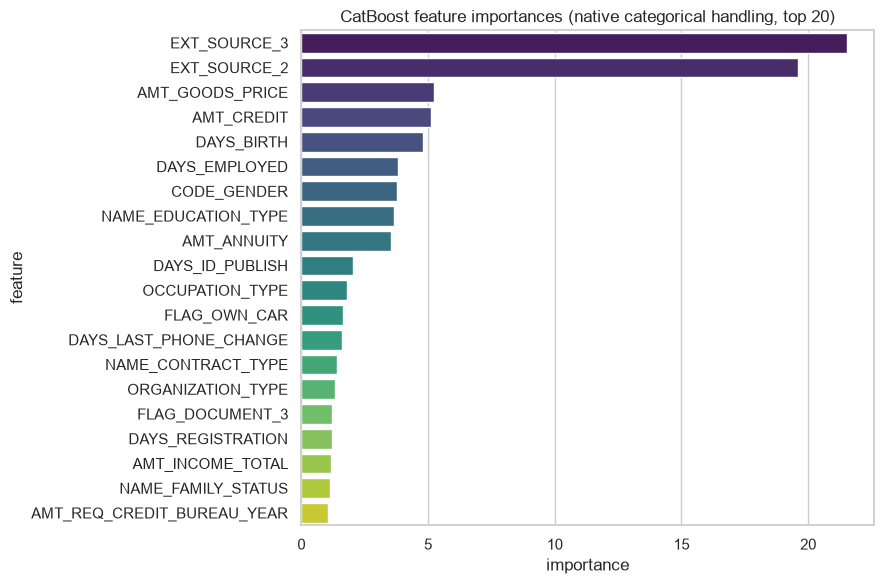

,feature,importance
27,EXT_SOURCE_3,21.522389
26,EXT_SOURCE_2,19.597260
4,AMT_GOODS_PRICE,5.237785
2,AMT_CREDIT,5.128466
6,DAYS_BIRTH,4.813389
7,DAYS_EMPLOYED,3.810083
67,CODE_GENDER,3.782219
72,NAME_EDUCATION_TYPE,3.670558
3,AMT_ANNUITY,3.530882
9,DAYS_ID_PUBLISH,2.032966


In [28]:
cat_importance = pd.DataFrame({"feature": X_train.columns, "importance": cat.get_feature_importance()}
                               ).sort_values("importance", ascending=False).head(20)
plt.figure(figsize=(9, 6))
sns.barplot(data=cat_importance, x="importance", y="feature", palette="viridis")
plt.title("CatBoost feature importances (native categorical handling, top 20)")
plt.tight_layout()
plt.show()
cat_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [29]:
cat_param_dist = {'iterations': [500], 'depth': [4, 6], 'learning_rate': [0.03, 0.05]}


cat_search = RandomizedSearchCV(
    CatBoostClassifier(l2_leaf_reg=3.0, random_seed=RANDOM_STATE, thread_count=1, allow_writing_files=False, verbose=False),
    param_distributions=cat_param_dist, n_iter=2, cv=skf3, scoring="roc_auc",
    n_jobs=2, random_state=RANDOM_STATE,
)
cat_search.fit(X_train, y_train, cat_features=cat_feature_idx)
print(f"Best params: {cat_search.best_params_}")
print(f"Best CV ROC-AUC: {cat_search.best_score_:.4f}")


Best params: {'learning_rate': 0.05, 'iterations': 500, 'depth': 6}
Best CV ROC-AUC: 0.7501


In [30]:
y_proba_cat_tuned = cat_search.best_estimator_.predict_proba(X_test)[:, 1]
evaluate("CatBoost (tuned)", y_test, y_proba_cat_tuned)


CatBoost (tuned)      ROC_AUC=0.7558  F1=0.0298  Precision=0.5802  Recall=0.0153


{'ROC_AUC': 0.7558497440625537,
 'Accuracy': 0.9196136773815912,
 'Precision': 0.5801526717557252,
 'Recall': 0.015307150050352467,
 'F1': 0.029827315541601257,
 'LogLoss': 0.24666543693439086}

## 11. LightGBM (Light Gradient Boosting Machine)


In [31]:
lgbm = LGBMClassifier(n_estimators=500, learning_rate=0.05, num_leaves=31,
                       min_child_samples=20, subsample=0.8, colsample_bytree=0.8,
                       random_state=RANDOM_STATE, n_jobs=2, verbose=-1)
lgbm.fit(X_train_enc, y_train, eval_set=[(X_test_enc, y_test)])
y_proba_lgbm = lgbm.predict_proba(X_test_enc)[:, 1]
evaluate("LightGBM", y_test, y_proba_lgbm)


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM              ROC_AUC=0.7559  F1=0.0389  Precision=0.5682  Recall=0.0201


{'ROC_AUC': 0.7559431104932519,
 'Accuracy': 0.919662455489976,
 'Precision': 0.5681818181818182,
 'Recall': 0.02014098690835851,
 'F1': 0.03890293717175647,
 'LogLoss': 0.2464248869516287}

/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98159/4290498733.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=lgbm_importance, x="importance", y="feature", palette="viridis")


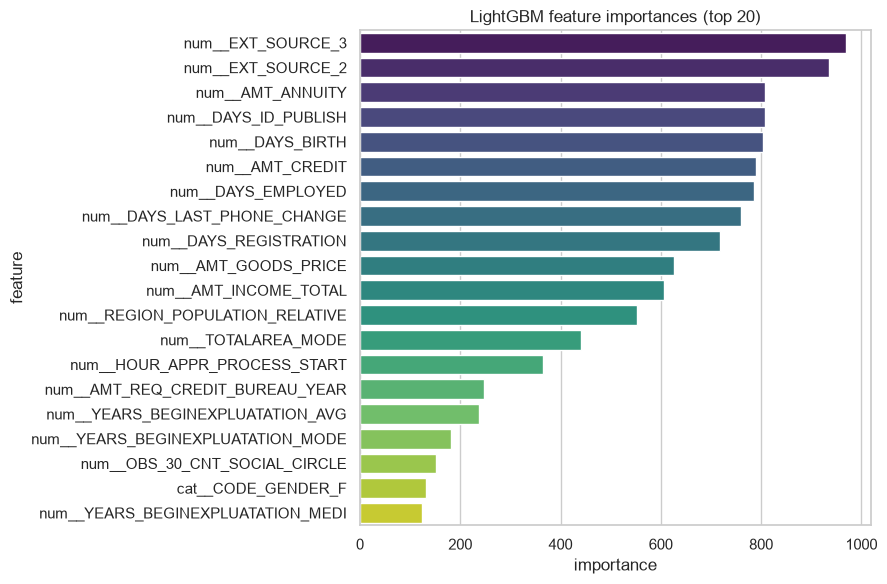

,feature,importance
27,num__EXT_SOURCE_3,970
26,num__EXT_SOURCE_2,935
3,num__AMT_ANNUITY,808
9,num__DAYS_ID_PUBLISH,807
6,num__DAYS_BIRTH,803
2,num__AMT_CREDIT,790
7,num__DAYS_EMPLOYED,785
39,num__DAYS_LAST_PHONE_CHANGE,760
8,num__DAYS_REGISTRATION,719
4,num__AMT_GOODS_PRICE,626


In [32]:
lgbm_importance = pd.DataFrame({"feature": tree_feature_names, "importance": lgbm.feature_importances_}
                                ).sort_values("importance", ascending=False).head(20)
plt.figure(figsize=(9, 6))
sns.barplot(data=lgbm_importance, x="importance", y="feature", palette="viridis")
plt.title("LightGBM feature importances (top 20)")
plt.tight_layout()
plt.show()
lgbm_importance


### Hyperparameter tuning with `RandomizedSearchCV`

Fit the search on the training data and compare the selected model on the held-out partition.

In [33]:
lgbm_param_dist = {'n_estimators': [500], 'num_leaves': [15, 31], 'learning_rate': [0.03, 0.05]}


lgbm_search = RandomizedSearchCV(
    LGBMClassifier(subsample=0.8, colsample_bytree=0.8, min_child_samples=20,
                   random_state=RANDOM_STATE, n_jobs=2, verbose=-1),
    param_distributions=lgbm_param_dist, n_iter=2, cv=skf3, scoring="roc_auc",
    n_jobs=2, random_state=RANDOM_STATE,
)
lgbm_search.fit(X_train_enc, y_train)
print(f"Best params: {lgbm_search.best_params_}")
print(f"Best CV ROC-AUC: {lgbm_search.best_score_:.4f}")


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Best params: {'num_leaves': 31, 'n_estimators': 500, 'learning_rate': 0.03}
Best CV ROC-AUC: 0.7477


In [34]:
y_proba_lgbm_tuned = lgbm_search.best_estimator_.predict_proba(X_test_enc)[:, 1]
evaluate("LightGBM (tuned)", y_test, y_proba_lgbm_tuned)


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


LightGBM (tuned)      ROC_AUC=0.7562  F1=0.0271  Precision=0.5610  Recall=0.0139


{'ROC_AUC': 0.7561654707220948,
 'Accuracy': 0.9195161211648212,
 'Precision': 0.5609756097560976,
 'Recall': 0.013897280966767372,
 'F1': 0.027122641509433963,
 'LogLoss': 0.24652489334646221}

## 12. Head-to-head comparison


In [35]:
results_df = pd.DataFrame(results).T.sort_values("ROC_AUC", ascending=False)
results_df


,ROC_AUC,Accuracy,Precision,Recall,F1,LogLoss
XGBoost,0.757915,0.919597,0.558140,0.019335,0.037376,0.245982
XGBoost (tuned),0.756451,0.919744,0.617886,0.015307,0.029874,0.246398
LightGBM (tuned),0.756165,0.919516,0.560976,0.013897,0.027123,0.246525
LightGBM,0.755943,0.919662,0.568182,0.020141,0.038903,0.246425
CatBoost,0.755850,0.919614,0.580153,0.015307,0.029827,0.246665
CatBoost (tuned),0.755850,0.919614,0.580153,0.015307,0.029827,0.246665
LogisticRegression,0.745908,0.919467,0.557692,0.011682,0.022884,0.249638
LogReg (L1),0.744285,0.919402,0.544444,0.009869,0.019387,0.250160
MLP,0.743177,0.919158,0.456790,0.007452,0.014665,0.252633
MLP (tuned),0.739953,0.918671,0.435986,0.025378,0.047963,0.253193


/var/folders/y3/srk56slx1yzgjhrlxm_ttxx80000gn/T/ipykernel_98159/1082542411.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=results_df.loc[order, "ROC_AUC"], y=order, palette="viridis", ax=axes[0])


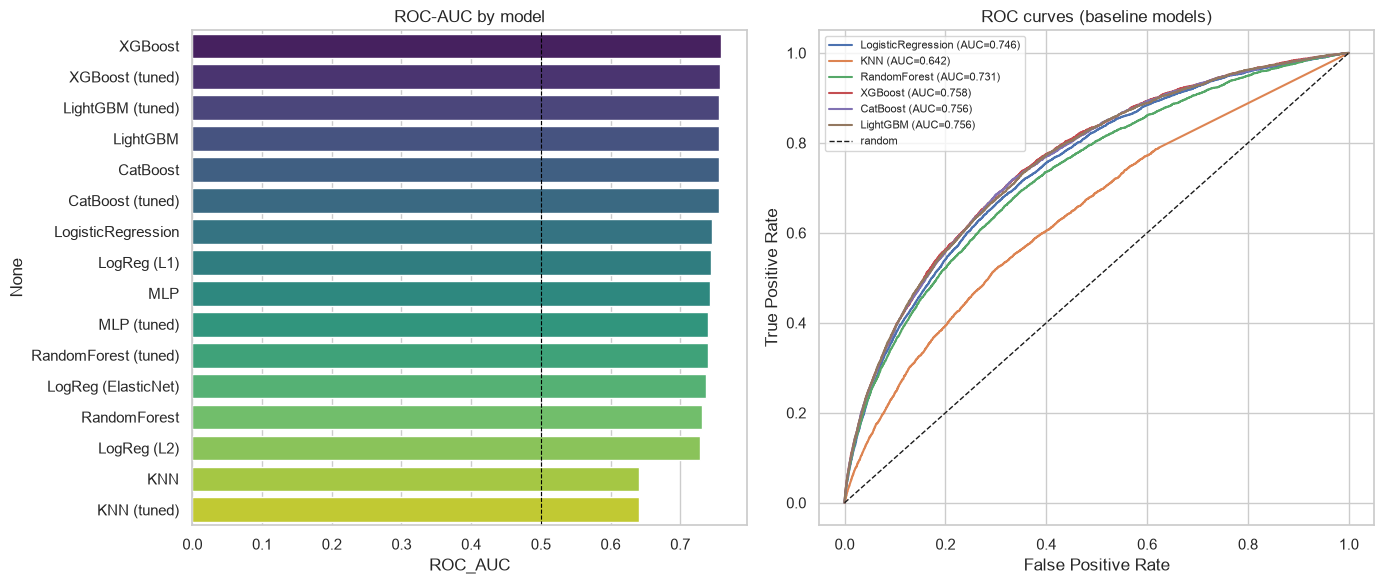

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
order = results_df.index
sns.barplot(x=results_df.loc[order, "ROC_AUC"], y=order, palette="viridis", ax=axes[0])
axes[0].set_title("ROC-AUC by model")
axes[0].axvline(0.5, color="black", linewidth=0.8, linestyle="--")

probas = {"LogisticRegression": y_proba_lr, "KNN": y_proba_knn, "RandomForest": y_proba_rf,
          "XGBoost": y_proba_xgb, "CatBoost": y_proba_cat, "LightGBM": y_proba_lgbm}
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, p):.3f})")
axes[1].plot([0, 1], [0, 1], "k--", linewidth=1, label="random")
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC curves (baseline models)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()


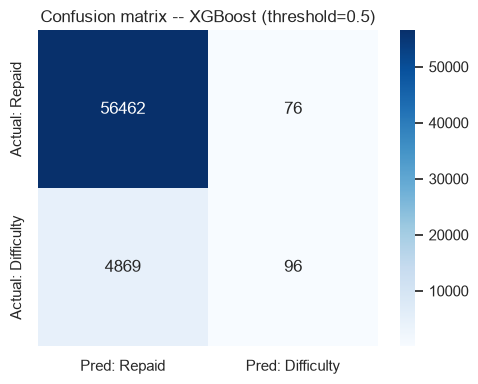

At the default 0.5 threshold, XGBoost catches 96/4965 (1.9%) of applicants who'll have payment difficulty.


In [37]:
best_model_name = results_df.index[0]
best_proba = {**probas, "MLP": y_proba_mlp, "MLP (tuned)": y_proba_mlp_tuned,
              "RandomForest (tuned)": y_proba_rf_tuned, "XGBoost (tuned)": y_proba_xgb_tuned,
              "CatBoost (tuned)": y_proba_cat_tuned, "LightGBM (tuned)": y_proba_lgbm_tuned}[best_model_name]

cm = confusion_matrix(y_test, (best_proba >= 0.5).astype(int))
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred: Repaid", "Pred: Difficulty"],
            yticklabels=["Actual: Repaid", "Actual: Difficulty"])
plt.title(f"Confusion matrix -- {best_model_name} (threshold=0.5)")
plt.tight_layout()
plt.show()

print(f"At the default 0.5 threshold, {best_model_name} catches "
      f"{cm[1,1]}/{cm[1].sum()} ({cm[1,1]/cm[1].sum():.1%}) of applicants who'll have payment difficulty.")


## 13. Stacking

Combine Random Forest, XGBoost and LightGBM with a linear meta-model. The meta-model learns from out-of-fold predictions within the training partition. Compare the resulting ensemble with the individual models on the held-out partition.

In [38]:
from sklearn.ensemble import StackingClassifier

stack = StackingClassifier(
    estimators=[("forest", rf), ("xgboost", xgb), ("lightgbm", lgbm)],
    final_estimator=LogisticRegression(C=1.0, max_iter=2000, random_state=RANDOM_STATE),
    cv=2,
    n_jobs=2,
)
stack.fit(X_train_scaled, y_train)
y_proba_stack = stack.predict_proba(X_test_scaled)[:, 1]
evaluate("Stacking", y_test, y_proba_stack)


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


/Users/ltd/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Stacking              ROC_AUC=0.7531  F1=0.0988  Precision=0.4884  Recall=0.0550


{'ROC_AUC': 0.7531354416712381,
 'Accuracy': 0.919060858819895,
 'Precision': 0.4883720930232558,
 'Recall': 0.05498489425981873,
 'F1': 0.09884141926140477,
 'LogLoss': 0.25036744221350404}

## 14. Conclusion

Use the measured comparison to discuss accuracy, interpretability and training cost. Regularized linear models are useful references for correlated inputs. KNN depends on the distance representation. MLP needs scaling and optimization checks. Tree ensembles capture nonlinear interactions, and stacking adds a meta-model trained on out-of-fold predictions.

Report the best measured result together with its metric and validation design. Inspect errors within important target ranges or groups before choosing a model for a new population.

In [39]:
final_results = pd.DataFrame(results).T.sort_values('ROC_AUC', ascending=False)
print("Results from this run")
display(final_results)


Results from this run


,ROC_AUC,Accuracy,Precision,Recall,F1,LogLoss
XGBoost,0.757915,0.919597,0.558140,0.019335,0.037376,0.245982
XGBoost (tuned),0.756451,0.919744,0.617886,0.015307,0.029874,0.246398
LightGBM (tuned),0.756165,0.919516,0.560976,0.013897,0.027123,0.246525
LightGBM,0.755943,0.919662,0.568182,0.020141,0.038903,0.246425
CatBoost (tuned),0.755850,0.919614,0.580153,0.015307,0.029827,0.246665
CatBoost,0.755850,0.919614,0.580153,0.015307,0.029827,0.246665
Stacking,0.753135,0.919061,0.488372,0.054985,0.098841,0.250367
LogisticRegression,0.745908,0.919467,0.557692,0.011682,0.022884,0.249638
LogReg (L1),0.744285,0.919402,0.544444,0.009869,0.019387,0.250160
MLP,0.743177,0.919158,0.456790,0.007452,0.014665,0.252633
